# IMPORT_LIBRARIES

In [3]:
import optuna
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


from catboost import CatBoostClassifier
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    log_loss,
    confusion_matrix,
    classification_report
)

In [1]:
def data_info(data):

    """
    This function returns a DataFrame containing the summary information for each column
    """

    Names=[col for col in data]
    data_types=[data[col].dtype for col in data.columns]
    top_10_unique_values=[data[col].value_counts().head(10).index.to_list() for col in data.columns]
    nunique_values=[data[col].nunique() for col in data.columns]
    nulls=[data[col].isnull().sum() for col in data.columns]
    percent_of_Nulls= [data[col].isnull().sum()/len(data)*100 for col in data.columns]
    duplicates=data.duplicated().sum()


    info_df=pd.DataFrame({'Name':Names,
                          'Data_Type':data_types,
                          'Top_10_Unique_Values':top_10_unique_values,
                          'Nunique_Values':nunique_values,
                          'Nulls':nulls,
                          'Percent_of_Nulls':percent_of_Nulls,
                          'Duplicates':duplicates})
    return info_df

# Load_Data

In [4]:
train_df = pd.read_csv("preprocessed_train_pca.csv")
test_df = pd.read_csv("preprocessed_test_pca.csv")

In [5]:
data_info(train_df)

,Name,Data_Type,Top_10_Unique_Values,Nunique_Values,Nulls,Percent_of_Nulls,Duplicates
0,PC01,float64,"[-0.3807000348447774, 2.5678421540697283, 0.07...",43335,0,0.0,4540
1,PC02,float64,"[7.09709923799542, 5.933796459126948, 7.564720...",43335,0,0.0,4540
2,PC03,float64,"[-0.4433470819902003, -2.963392633242212, -0.4...",43335,0,0.0,4540
3,PC04,float64,"[2.517459169051467, -3.1871496057192825, 2.453...",43335,0,0.0,4540
4,PC05,float64,"[1.540804961895072, -4.277464325500423, 1.9950...",43335,0,0.0,4540
5,PC06,float64,"[-0.7956875891268457, -4.417707498169771, -0.8...",43335,0,0.0,4540
6,PC07,float64,"[0.6415305056840194, -1.7810833188189037, 0.43...",43334,0,0.0,4540
7,PC08,float64,"[-0.0229196443167372, -0.3189250012478343, 0.0...",43335,0,0.0,4540
8,PC09,float64,"[-1.470524058424849, -1.8031224841234064, -1.2...",43335,0,0.0,4540
9,PC10,float64,"[0.8362002014527632, -0.2555122028012979, 0.03...",43334,0,0.0,4540


In [6]:
data_info(test_df)

,Name,Data_Type,Top_10_Unique_Values,Nunique_Values,Nulls,Percent_of_Nulls,Duplicates
0,PC01,float64,"[1.4258368197888196, 1.6871986060928967, -4.32...",11959,0,0.0,11
1,PC02,float64,"[-4.342656233365043, -4.3578498545064654, 1.27...",11959,0,0.0,11
2,PC03,float64,"[-5.101145947445104, -2.672443110314275, -0.43...",11959,0,0.0,11
3,PC04,float64,"[0.8224923180163427, -0.3991876967493648, 0.69...",11959,0,0.0,11
4,PC05,float64,"[-0.0989809473199084, 1.8647632523114044, 1.00...",11959,0,0.0,11
5,PC06,float64,"[-0.3026188824516937, 1.0320795193295949, 0.66...",11959,0,0.0,11
6,PC07,float64,"[0.059924706331041, 1.6766950892994483, -0.013...",11959,0,0.0,11
7,PC08,float64,"[3.816085258041243, 2.013980152933601, 0.05293...",11959,0,0.0,11
8,PC09,float64,"[1.025021703390861, -0.0601306088093717, -2.42...",11959,0,0.0,11
9,PC10,float64,"[0.5233062272199646, -0.3463994466999625, 1.26...",11959,0,0.0,11


In [7]:
train_df = train_df.drop_duplicates()
test_df = test_df.drop_duplicates()

# Spilitng

In [8]:
X = train_df.drop(columns=["target"])
y = train_df["target"]

X_test = test_df.drop(columns=["target"])
y_test = test_df["target"]

In [9]:
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [11]:
print("=" * 65)
print("DATA SUMMARY")
print("=" * 65)
print("Training samples  :", len(X_train))
print("Validation samples:", len(X_val))
print("Test samples      :", len(X_test))
print("Features          :", X_train.shape[1])

DATA SUMMARY
Training samples  : 34668
Validation samples: 8667
Test samples      : 11959
Features          : 25


In [ ]:
print("=" * 50)
print("CHECKING DATA")
print("=" * 50)

print("X_train:", X_train.shape)
print("X_val  :", X_val.shape)
print("X_test :", X_test.shape)

print("y_train:", y_train.shape)
print("y_val  :", y_val.shape)
print("y_test :", y_test.shape)


CHECKING DATA
X_train: (34668, 25)
X_val  : (8667, 25)
X_test : (11959, 25)
y_train: (34668,)
y_val  : (8667,)
y_test : (11959,)


#  SVM HYPERPARAMETER OPTIMIZATION

In [12]:
def svm_objective(trial):
    params = {
        'C': trial.suggest_float('C', 0.1, 100.0, log=True),
        'gamma': trial.suggest_float('gamma', 1e-4, 1.0, log=True),
        'kernel': trial.suggest_categorical('kernel', ['rbf', 'linear']),
        'probability': True,  
        'random_state': 42
    }
    
   
    model = SVC(**params)
    model.fit(X_train, y_train)
    
    preds_proba = model.predict_proba(X_val)[:, 1]
    val_auc = roc_auc_score(y_val, preds_proba)
    
    print(f" [SVM Trial {trial.number:02d}] Validation AUC: {val_auc:.6f}")
    return val_auc


svm_study = optuna.create_study(direction='maximize')
svm_study.optimize(svm_objective, n_trials=20, timeout=600)

print("\n" + "="*65)
print(" SVM OPTIMIZATION COMPLETED! COPY THESE BEST PARAMETERS:")
print("="*65)
for k, v in svm_study.best_params.items():
    print(f"'{k}': {v},")
print(f"Best SVM Validation AUC Score: {svm_study.best_value:.6f}")
print("="*65)

[I 2026-10-16 11:50:12,483] A new study created in memory with name: no-name-1fd819a5-4431-4d57-b282-6ccb60efc5c6
c:\Users\MAKKA\anaconda3\envs\ml_master\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
[I 2026-10-16 11:51:16,125] Trial 0 finished with value: 0.9997269426022466 and parameters: {'C': 41.74780086848928, 'gamma': 0.00045034542116702037, 'kernel': 'linear'}. Best is trial 0 with value: 0.9997269426022466.


 [SVM Trial 00] Validation AUC: 0.999727


c:\Users\MAKKA\anaconda3\envs\ml_master\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
[I 2026-10-16 11:51:33,956] Trial 1 finished with value: 0.9997231545844192 and parameters: {'C': 0.43605552108757933, 'gamma': 0.012843261084173234, 'kernel': 'rbf'}. Best is trial 0 with value: 0.9997269426022466.


 [SVM Trial 01] Validation AUC: 0.999723


c:\Users\MAKKA\anaconda3\envs\ml_master\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
[I 2026-10-16 11:52:05,973] Trial 2 finished with value: 0.9997281697066133 and parameters: {'C': 13.203271430564374, 'gamma': 0.0013073494780125718, 'kernel': 'linear'}. Best is trial 2 with value: 0.9997281697066133.


 [SVM Trial 02] Validation AUC: 0.999728


c:\Users\MAKKA\anaconda3\envs\ml_master\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
[I 2026-10-16 11:52:16,377] Trial 3 finished with value: 0.9997445488822893 and parameters: {'C': 1.321046230567647, 'gamma': 0.2311783692302375, 'kernel': 'linear'}. Best is trial 3 with value: 0.9997445488822893.


 [SVM Trial 03] Validation AUC: 0.999745


c:\Users\MAKKA\anaconda3\envs\ml_master\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
[I 2026-10-16 11:54:07,368] Trial 4 finished with value: 0.9997264624309727 and parameters: {'C': 87.79057454004958, 'gamma': 0.8398618132930312, 'kernel': 'linear'}. Best is trial 3 with value: 0.9997445488822893.


 [SVM Trial 04] Validation AUC: 0.999726


c:\Users\MAKKA\anaconda3\envs\ml_master\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
[I 2026-10-16 11:54:34,304] Trial 5 finished with value: 0.9997313708484391 and parameters: {'C': 11.032303914009342, 'gamma': 0.0004880020147698581, 'kernel': 'linear'}. Best is trial 3 with value: 0.9997445488822893.


 [SVM Trial 05] Validation AUC: 0.999731


c:\Users\MAKKA\anaconda3\envs\ml_master\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
[I 2026-10-16 11:54:43,633] Trial 6 finished with value: 0.9997446555870169 and parameters: {'C': 1.2292551819424369, 'gamma': 0.004879122693174889, 'kernel': 'linear'}. Best is trial 6 with value: 0.9997446555870169.


 [SVM Trial 06] Validation AUC: 0.999745


c:\Users\MAKKA\anaconda3\envs\ml_master\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
[I 2026-10-16 11:54:51,129] Trial 7 finished with value: 0.9998395160897925 and parameters: {'C': 42.26193557044826, 'gamma': 0.001130798533633969, 'kernel': 'rbf'}. Best is trial 7 with value: 0.9998395160897925.


 [SVM Trial 07] Validation AUC: 0.999840


c:\Users\MAKKA\anaconda3\envs\ml_master\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
[I 2026-10-16 11:55:01,596] Trial 8 finished with value: 0.9998128932602732 and parameters: {'C': 44.44004719555841, 'gamma': 0.00021781778544540097, 'kernel': 'rbf'}. Best is trial 7 with value: 0.9998395160897925.


 [SVM Trial 08] Validation AUC: 0.999813


c:\Users\MAKKA\anaconda3\envs\ml_master\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
[I 2026-10-16 11:57:05,118] Trial 9 finished with value: 0.9987707615388357 and parameters: {'C': 0.14235418610485726, 'gamma': 0.06699728724225172, 'kernel': 'rbf'}. Best is trial 7 with value: 0.9998395160897925.


 [SVM Trial 09] Validation AUC: 0.998771


c:\Users\MAKKA\anaconda3\envs\ml_master\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
[I 2026-10-16 11:57:24,707] Trial 10 finished with value: 0.9991945927165914 and parameters: {'C': 25.05101509363482, 'gamma': 0.0236124234080886, 'kernel': 'rbf'}. Best is trial 7 with value: 0.9998395160897925.


 [SVM Trial 10] Validation AUC: 0.999195


c:\Users\MAKKA\anaconda3\envs\ml_master\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
[I 2026-10-16 11:57:35,526] Trial 11 finished with value: 0.9998124130889994 and parameters: {'C': 33.836484318194515, 'gamma': 0.00020988368818174695, 'kernel': 'rbf'}. Best is trial 7 with value: 0.9998395160897925.


 [SVM Trial 11] Validation AUC: 0.999812


c:\Users\MAKKA\anaconda3\envs\ml_master\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
[I 2026-10-16 11:57:42,599] Trial 12 finished with value: 0.9995957491397465 and parameters: {'C': 86.0966610468157, 'gamma': 0.0018127738750232988, 'kernel': 'rbf'}. Best is trial 7 with value: 0.9998395160897925.


 [SVM Trial 12] Validation AUC: 0.999596


c:\Users\MAKKA\anaconda3\envs\ml_master\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
[I 2026-10-16 11:57:58,788] Trial 13 finished with value: 0.9998053172246186 and parameters: {'C': 3.3155185732035126, 'gamma': 0.00039715013607616274, 'kernel': 'rbf'}. Best is trial 7 with value: 0.9998395160897925.


 [SVM Trial 13] Validation AUC: 0.999805


c:\Users\MAKKA\anaconda3\envs\ml_master\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
[I 2026-10-16 11:58:08,463] Trial 14 finished with value: 0.9998413834225243 and parameters: {'C': 3.5901898746297247, 'gamma': 0.0046554986157628375, 'kernel': 'rbf'}. Best is trial 14 with value: 0.9998413834225243.


 [SVM Trial 14] Validation AUC: 0.999841


c:\Users\MAKKA\anaconda3\envs\ml_master\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
[I 2026-10-16 11:58:17,674] Trial 15 finished with value: 0.9998610704447539 and parameters: {'C': 6.424255441154786, 'gamma': 0.001720756167759887, 'kernel': 'rbf'}. Best is trial 15 with value: 0.9998610704447539.


 [SVM Trial 15] Validation AUC: 0.999861


c:\Users\MAKKA\anaconda3\envs\ml_master\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
[I 2026-10-16 11:58:27,733] Trial 16 finished with value: 0.9998497597436354 and parameters: {'C': 3.979599530449194, 'gamma': 0.003994514636960834, 'kernel': 'rbf'}. Best is trial 15 with value: 0.9998610704447539.


 [SVM Trial 16] Validation AUC: 0.999850


c:\Users\MAKKA\anaconda3\envs\ml_master\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
[I 2026-10-16 11:59:38,276] Trial 17 finished with value: 0.9994989679518753 and parameters: {'C': 0.17516940024725405, 'gamma': 0.0002529912414665768, 'kernel': 'rbf'}. Best is trial 15 with value: 0.9998610704447539.


 [SVM Trial 17] Validation AUC: 0.999499


c:\Users\MAKKA\anaconda3\envs\ml_master\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
[I 2026-10-16 12:02:23,782] Trial 18 finished with value: 0.9995475186029021 and parameters: {'C': 6.208571573114556, 'gamma': 0.06853471165647451, 'kernel': 'rbf'}. Best is trial 15 with value: 0.9998610704447539.


 [SVM Trial 18] Validation AUC: 0.999548

 SVM OPTIMIZATION COMPLETED! COPY THESE BEST PARAMETERS:
'C': 6.424255441154786,
'gamma': 0.001720756167759887,
'kernel': rbf,
Best SVM Validation AUC Score: 0.999861


In [ ]:
# svm_best_params = {
#     'C': 6.424255441154786,           
#     'gamma': 0.001720756167759887,        
#     'kernel': 'rbf',      
#     'probability': True,
#     'random_state': 42
# }

# final_svm = SVC(**svm_best_params)
# final_svm.fit(X_train, y_train)

c:\Users\MAKKA\anaconda3\envs\ml_master\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",6.424255441154786
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",0.001720756167759887
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",True
,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo random number generation for shuffling the data forprobability estimates. Ignored when `probability` is False.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None


In [17]:
svm_best_params = {
    'C': 10.0,           
    'gamma': 0.01,        
    'kernel': 'rbf',      
    'probability': True,
    'random_state': 42
}

final_svm = SVC(**svm_best_params)
final_svm.fit(X_train, y_train)

c:\Users\MAKKA\anaconda3\envs\ml_master\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",10.0
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",0.01
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",True
,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo random number generation for shuffling the data forprobability estimates. Ignored when `probability` is False.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None


 SVM Test AUC Score        : 0.99970
 SVM Test Accuracy         : 0.99824
 SVM Test F1-Score (Weight): 0.99824

 SVM Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      5671
           1       1.00      1.00      1.00      6288

    accuracy                           1.00     11959
   macro avg       1.00      1.00      1.00     11959
weighted avg       1.00      1.00      1.00     11959



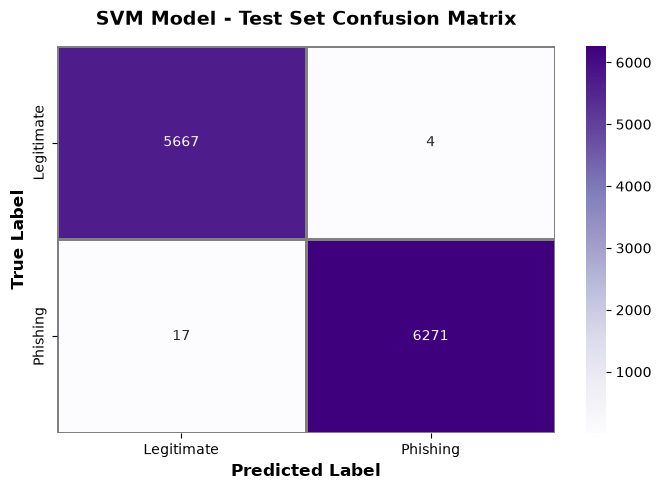

In [18]:
svm_test_probs = final_svm.predict_proba(X_test)[:, 1]
svm_test_preds = final_svm.predict(X_test)

print(f" SVM Test AUC Score        : {roc_auc_score(y_test, svm_test_probs):.5f}")
print(f" SVM Test Accuracy         : {accuracy_score(y_test, svm_test_preds):.5f}")
print(f" SVM Test F1-Score (Weight): {f1_score(y_test, svm_test_preds, average='weighted'):.5f}")

print("\n SVM Classification Report:")
print(classification_report(y_test, svm_test_preds))

plt.figure(figsize=(7, 5))
cm_svm = confusion_matrix(y_test, svm_test_preds)
sns.heatmap(cm_svm, annot=True, fmt='d', cmap='Purples', linewidths=1, linecolor='gray',
            xticklabels=['Legitimate', 'Phishing'],
            yticklabels=['Legitimate', 'Phishing'])

plt.title('SVM Model - Test Set Confusion Matrix', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Predicted Label', fontsize=12, fontweight='bold')
plt.ylabel('True Label', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()